<a href="https://colab.research.google.com/github/Prajnaa002/Applied_Probability_and_Statistics/blob/main/APS_Sep23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#PROBLEM STATEMENT 1

##Step 1: Identify the random variable Answer the following:

###What does X=1 represent?
\(X\) represents the outcome of a customer's click on the promotional email link.

###What does X=0 represent?
\(X\) represents the outcome of a customer's no clicks on the promotional email link.

###What are the possible values of X ?
Since there are only two possible outcomes:
- \(X = 1\): Customer clicks the link.
- \(X = 0\): Customer does not click the link.

###Is a discrete or continuous random variable?
\(X\) is a discrete random variable because it can take only the values 0 and 1.

###Which probability distribution is suitable for ?
The Bernoulli distribution is suitable because there are exactly two possible outcomes: click or no click.

##Step 2: Write the theoretical PMF

P(X=0) = 0.7

P(X=1) = 0.3

##Step 3: Generate outcomes for 20 customers. Hint: np.random.binomial(n=1, ...) generates Bernoulli observations because only one trial is performed for each customer.

Use code: samples = np.random.binomial( n=1, p=p, size=sample_size )

Answer the following:

###How many observations were generated?  
20

###What does each zero represent?  
not clicks

###What does each one represent?  
clicks

###Are your generated observations the same as the theoretical probabilities?

P(X=1) = 6/20 = 0.3

In [ ]:
import numpy as np

p = 0.3
sample_size = 20

samples = np.random.binomial( n=1, p=p, size=sample_size )

print(samples)

[1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1]


##Step 4: Count clicks and non-clicks

Complete the code

number_of_clicks = np.sum(samples == _____)



number_of_non_clicks = np.sum(samples == _____)



print("Number of clicks:", number_of_clicks)

print("Number of non-clicks:", number_of_non_clicks)

Answer:

###How many customers clicked?  
4

###How many customers did not click?  
16

###Do the two counts add up to 20?
Yes, 4+16 = 20

In [ ]:
number_of_clicks = np.sum(samples == 1)

number_of_non_clicks = np.sum(samples == 0)

print("Number of clicks:", number_of_clicks)

print("Number of non-clicks:", number_of_non_clicks)

Number of clicks: 5
Number of non-clicks: 15


##Step 5: Calculate the empirical PMF

In [ ]:
emperical_pmf_0 = number_of_non_clicks/sample_size
emperical_pmf_1 = number_of_clicks/sample_size

print("Empirical PMF for 0:", emperical_pmf_0)
print("Empirical PMF for 1:", emperical_pmf_1)

Empirical PMF for 0: 0.75
Empirical PMF for 1: 0.25


##Step 6: Compare empirical and theoretical PMFs

Answer the following:

###Is the empirical probability of a click exactly
0.30
?  No, the empirical probability of a click is 0.2

###Which outcome has the larger probability?  
Non-click

###Why are the empirical and theoretical probabilities different?
The empirical and theoretical probabilities are different because the outcomes are randomly generated, and the sample size is small (20 customers). Random variation can cause the observed proportion of clicks to differ from the theoretical probability of 0.30

##Step 7: Plot empirical and theoretical PMFs

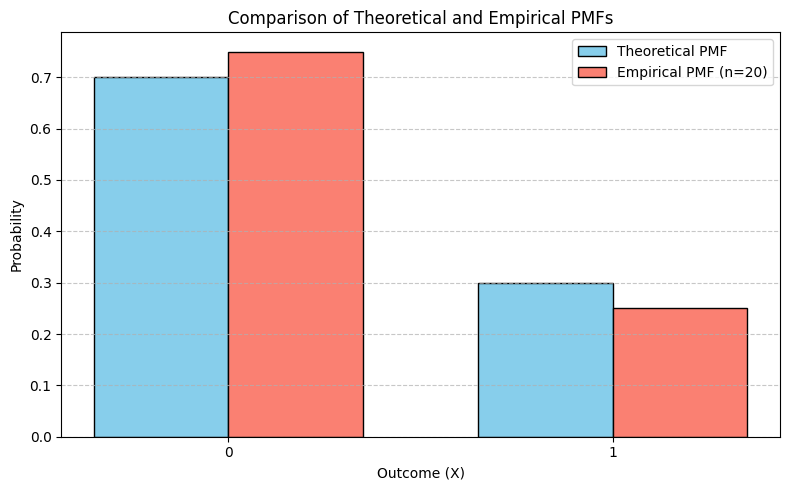

In [ ]:
import matplotlib.pyplot as plt
outcomes = [0, 1]
theoretical_pmf_0 = 0.7
theoretical_pmf_1 = 0.3
theo_pmfs = [theoretical_pmf_0, theoretical_pmf_1]
emp_pmfs = [emperical_pmf_0, emperical_pmf_1]

x = np.arange(len(outcomes))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, theo_pmfs, width, label='Theoretical PMF', color='skyblue', edgecolor='black')
plt.bar(x + width/2, emp_pmfs, width, label='Empirical PMF (n=20)', color='salmon', edgecolor='black')

plt.xlabel('Outcome (X)')
plt.ylabel('Probability')
plt.title('Comparison of Theoretical and Empirical PMFs')
plt.xticks(x, outcomes)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

##Step 8: Calculate the theoretical expectation

In [ ]:
theoretical_expectation = p
print("Theoretical expectation: ", theoretical_expectation)

Theoretical expectation:  0.3


##Step 9: Calculate the empirical expectation

In [ ]:
empirical_expectation = emperical_pmf_1
print("Empirical expectation: ", empirical_expectation)

Empirical expectation:  0.25


##Step 10: Calculate the theoretical variance

In [ ]:
theoretical_variance = theoretical_expectation * (1 - theoretical_expectation)
print("Theoretical variance: ", theoretical_variance)

Theoretical variance:  0.21


##Step 11: Calculate the empirical variance

In [ ]:
emperical_variance = emperical_pmf_1 * (1 - emperical_pmf_1)
print("Theoretical variance: ", emperical_variance)

Theoretical variance:  0.1875


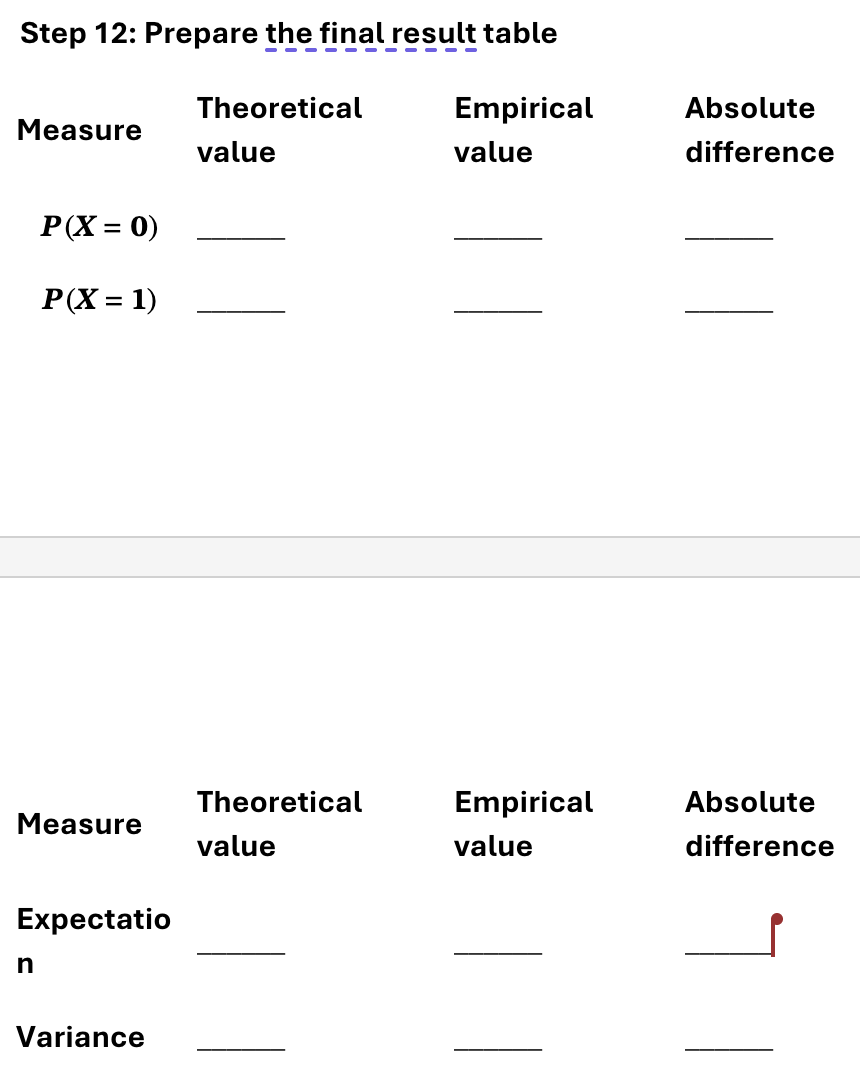

In [ ]:
import pandas as pd

results = {
    "Measure": [
        "P(X = 0)",
        "P(X = 1)",
        "Expectation",
        "Variance"
    ],
    "Theoretical Value": [
        0.70,
        0.30,
        theoretical_expectation,
        theoretical_variance
    ],
    "Emperical Value" : [
        emperical_pmf_0,
        emperical_pmf_1,
        np.mean(samples),
        emperical_variance
    ]
}

df = pd.DataFrame(results)
df["Absolute Difference"] = abs (df["Theoretical Value"] - df["Emperical Value"])
print(df)

       Measure  Theoretical Value  Emperical Value  Absolute Difference
0     P(X = 0)               0.70           0.7500               0.0500
1     P(X = 1)               0.30           0.2500               0.0500
2  Expectation               0.30           0.2500               0.0500
3     Variance               0.21           0.1875               0.0225


##Step13: Check Effect of sample size,
##Repeat the experiment n=10, 100, 1,000, 10,000

In [ ]:
sample_sizes = [10, 100, 1000, 10000]

result = []

for n in sample_sizes:
    samples_n = np.random.binomial(n=1, p=p, size=n)

    empirical_p0 = np.mean(samples_n == 0)
    empirical_p1 = np.mean(samples_n == 1)
    empirical_mean = np.mean(samples_n)
    empirical_variance = np.var(samples_n)

    result.append([
        n,
        empirical_p0,
        empirical_p1,
        empirical_mean,
        empirical_variance
    ])

result_df = pd.DataFrame(
    result,
    columns=[
        "Sample size",
        "Empirical P(X=0)",
        "Empirical P(X=1)",
        "Empirical mean",
        "Empirical variance"
    ]
)

print(result_df)

   Sample size  Empirical P(X=0)  Empirical P(X=1)  Empirical mean  \
0           10            0.8000            0.2000          0.2000   
1          100            0.6700            0.3300          0.3300   
2         1000            0.6940            0.3060          0.3060   
3        10000            0.6914            0.3086          0.3086   

   Empirical variance  
0            0.160000  
1            0.221100  
2            0.212364  
3            0.213366  


#PROBLEM STATEMENT 2

In [ ]:
n = 50
p = 0.04
sample_size = 20000

samples = np.random.binomial(
    n=n,
    p=p,
    size=sample_size
)

print(samples)
print("Number of simulated hours:", len(samples))
hours_exceeding_capacity = np.sum(samples > 4)

print("Hours exceeding capacity:", hours_exceeding_capacity)

[2 2 1 ... 1 3 0]
Number of simulated hours: 20000
Hours exceeding capacity: 968


In [ ]:
empirical_probability = hours_exceeding_capacity / sample_size

print("Empirical P(X > 4):", empirical_probability)
from scipy.stats import binom

n = 50
p = 0.04

theoretical_probability = 1 - binom.cdf(4, n, p)

print("Theoretical P(X > 4):", theoretical_probability)

Empirical P(X > 4): 0.0484
Theoretical P(X > 4): 0.048971471884512785


In [ ]:
theoretical_mean = n * p

print("Theoretical mean:", theoretical_mean)
empirical_mean = np.mean(samples)

print("Empirical mean:", empirical_mean)

Theoretical mean: 2.0
Empirical mean: 1.98815


In [ ]:
theoretical_variance = n * p * (1 - p)

print("Theoretical variance:", theoretical_variance)
empirical_variance = np.var(samples)

print("Empirical variance:", empirical_variance)


Theoretical variance: 1.92
Empirical variance: 1.9066095775000003


In [ ]:
problem2_table = pd.DataFrame({
    "Measure": [
        "P(X > 4)",
        "Expectation",
        "Variance"
    ],

    "Theoretical value": [
        theoretical_probability,
        theoretical_mean,
        theoretical_variance
    ],

    "Empirical value": [
        empirical_probability,
        empirical_mean,
        empirical_variance
    ]
})

problem2_table["Absolute difference"] = abs(
    problem2_table["Theoretical value"] -
    problem2_table["Empirical value"]
)

print(problem2_table.round(6).to_string(index=False))


    Measure  Theoretical value  Empirical value  Absolute difference
   P(X > 4)           0.048971          0.04840             0.000571
Expectation           2.000000          1.98815             0.011850
   Variance           1.920000          1.90661             0.013390
